# EMPLOYEE WELLBEING ANALYSIS
## Predicting Burnout Risks using Machine Learning

### Introduction:
The employee wellbeing is one of the most important aspects of a healthy workplace.
When employees are stressed, overworked or unhappy, it often leads to burnouts, which
directly affects the organization.
This project aims to explore and understand the factors that influence the employee
wellbeing using real world data.Using data analysis and machine learning, I aim to
identify patterns and predict burnout risk.

### Objectives:
 1. Perform the Exploratory Data Analysis(EDA) on the data.
 2. To visualize key patterns and relationships between the datapoints
 3. Conduct statistical tests
 4. To build and evaluate machine learning models for prediction

### Dataset Description
- Source: Kaggle
- Number of rows:
- Number of columns:
- Data features: 

### Methodology
- Data cleaning and preprocessing
- EDA
- Data Visualization
- Statistical Analysis
- Predictive Modeling

In [1]:
#core libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

In [2]:
#sklearn
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay,accuracy_score)
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV


In [3]:
df= pd.read_csv(r'C:\Users\ASUS\Downloads\archive\mental_health_workplace_survey.csv')
df

,EmployeeID,Age,Gender,Country,JobRole,Department,YearsAtCompany,WorkHoursPerWeek,RemoteWork,BurnoutLevel,...,CommuteTime,HasMentalHealthSupport,ManagerSupportScore,HasTherapyAccess,MentalHealthDaysOff,SalaryRange,WorkLifeBalanceScore,TeamSize,CareerGrowthScore,BurnoutRisk
0,1001,50,Male,UK,Sales Associate,HR,14,47,No,3.37,...,117,No,3.15,Yes,8,40K-60K,8.82,6,9.20,0
1,1002,36,Male,Germany,Software Engineer,IT,1,59,Hybrid,7.39,...,8,Yes,4.40,Yes,4,80K-100K,2.80,45,8.46,1
2,1003,29,Non-binary,India,IT Admin,IT,13,59,Hybrid,7.10,...,75,No,3.63,No,6,80K-100K,7.28,7,7.96,1
3,1004,42,Male,Australia,HR Specialist,IT,15,31,Yes,4.18,...,43,Yes,4.50,Yes,9,60K-80K,1.31,11,8.90,0
4,1005,40,Male,Brazil,Customer Support,Support,6,34,Yes,8.28,...,58,Yes,5.51,Yes,6,<40K,1.17,18,8.88,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,3996,28,Female,Brazil,Marketing Manager,Sales,18,46,No,2.86,...,4,Yes,6.97,No,1,80K-100K,7.71,21,7.70,0
2996,3997,24,Male,Brazil,Customer Support,Marketing,14,31,No,2.43,...,1,Yes,5.58,Yes,0,60K-80K,3.76,2,2.59,0
2997,3998,22,Female,Canada,Marketing Manager,Marketing,0,38,No,6.87,...,25,No,3.81,No,0,40K-60K,3.03,2,6.95,0
2998,3999,57,Non-binary,Australia,Data Scientist,HR,2,41,No,3.62,...,24,No,9.72,No,3,100K+,6.02,37,9.06,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   EmployeeID              3000 non-null   int64  
 1   Age                     3000 non-null   int64  
 2   Gender                  3000 non-null   str    
 3   Country                 3000 non-null   str    
 4   JobRole                 3000 non-null   str    
 5   Department              3000 non-null   str    
 6   YearsAtCompany          3000 non-null   int64  
 7   WorkHoursPerWeek        3000 non-null   int64  
 8   RemoteWork              3000 non-null   str    
 9   BurnoutLevel            3000 non-null   float64
 10  JobSatisfaction         3000 non-null   float64
 11  StressLevel             3000 non-null   float64
 12  ProductivityScore       3000 non-null   float64
 13  SleepHours              3000 non-null   float64
 14  PhysicalActivityHrs     3000 non-null   float64
 15

In [5]:
df.isna().sum()

EmployeeID                0
Age                       0
Gender                    0
Country                   0
JobRole                   0
Department                0
YearsAtCompany            0
WorkHoursPerWeek          0
RemoteWork                0
BurnoutLevel              0
JobSatisfaction           0
StressLevel               0
ProductivityScore         0
SleepHours                0
PhysicalActivityHrs       0
CommuteTime               0
HasMentalHealthSupport    0
ManagerSupportScore       0
HasTherapyAccess          0
MentalHealthDaysOff       0
SalaryRange               0
WorkLifeBalanceScore      0
TeamSize                  0
CareerGrowthScore         0
BurnoutRisk               0
dtype: int64

In [6]:
df.dtypes

EmployeeID                  int64
Age                         int64
Gender                        str
Country                       str
JobRole                       str
Department                    str
YearsAtCompany              int64
WorkHoursPerWeek            int64
RemoteWork                    str
BurnoutLevel              float64
JobSatisfaction           float64
StressLevel               float64
ProductivityScore         float64
SleepHours                float64
PhysicalActivityHrs       float64
CommuteTime                 int64
HasMentalHealthSupport        str
ManagerSupportScore       float64
HasTherapyAccess              str
MentalHealthDaysOff         int64
SalaryRange                   str
WorkLifeBalanceScore      float64
TeamSize                    int64
CareerGrowthScore         float64
BurnoutRisk                 int64
dtype: object

In [7]:
#Encoding the data
le = LabelEncoder()

# List of string columns to encode
cols = ['Gender', 'Country', 'JobRole', 'Department','RemoteWork', 'HasMentalHealthSupport','HasTherapyAccess', 'SalaryRange']
for col in cols:
    df[col] = le.fit_transform(df[col])
df.dtypes

EmployeeID                  int64
Age                         int64
Gender                      int64
Country                     int64
JobRole                     int64
Department                  int64
YearsAtCompany              int64
WorkHoursPerWeek            int64
RemoteWork                  int64
BurnoutLevel              float64
JobSatisfaction           float64
StressLevel               float64
ProductivityScore         float64
SleepHours                float64
PhysicalActivityHrs       float64
CommuteTime                 int64
HasMentalHealthSupport      int64
ManagerSupportScore       float64
HasTherapyAccess            int64
MentalHealthDaysOff         int64
SalaryRange                 int64
WorkLifeBalanceScore      float64
TeamSize                    int64
CareerGrowthScore         float64
BurnoutRisk                 int64
dtype: object

In [8]:
df.head()

,EmployeeID,Age,Gender,Country,JobRole,Department,YearsAtCompany,WorkHoursPerWeek,RemoteWork,BurnoutLevel,...,CommuteTime,HasMentalHealthSupport,ManagerSupportScore,HasTherapyAccess,MentalHealthDaysOff,SalaryRange,WorkLifeBalanceScore,TeamSize,CareerGrowthScore,BurnoutRisk
0,1001,50,1,5,6,1,14,47,1,3.37,...,117,0,3.15,1,8,1,8.82,6,9.20,0
1,1002,36,1,3,7,2,1,59,0,7.39,...,8,1,4.40,1,4,3,2.80,45,8.46,1
2,1003,29,2,4,3,2,13,59,0,7.10,...,75,0,3.63,0,6,3,7.28,7,7.96,1
3,1004,42,1,0,2,2,15,31,2,4.18,...,43,1,4.50,1,9,2,1.31,11,8.90,0
4,1005,40,1,1,0,5,6,34,2,8.28,...,58,1,5.51,1,6,4,1.17,18,8.88,1


## Data Visualisation

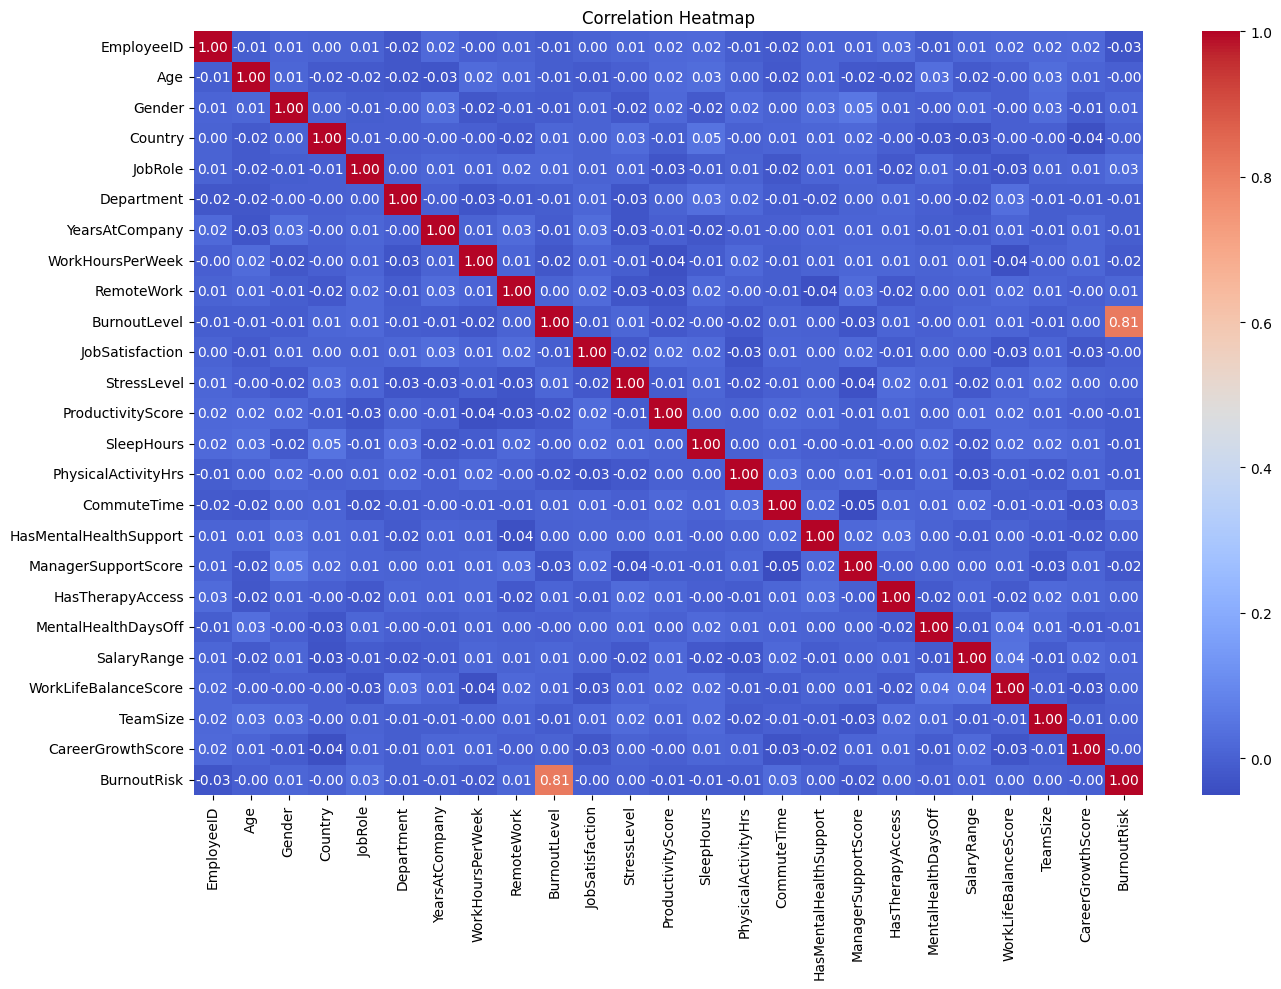

In [9]:
#correlation heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

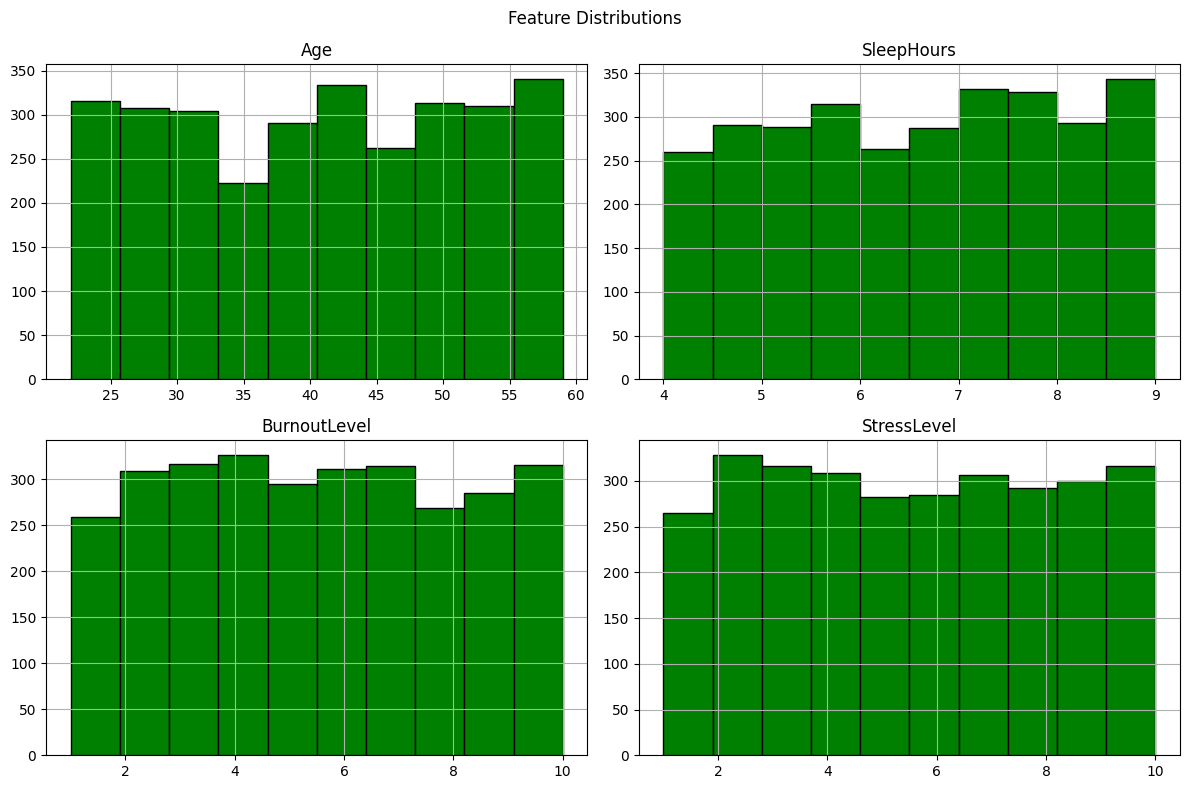

In [10]:
#histogram
cols = ['Age', 'SleepHours', 'BurnoutLevel', 'StressLevel']
df[cols].hist(figsize=(12, 8), color='green', edgecolor='black')
plt.suptitle('Feature Distributions')
plt.tight_layout()
plt.show()

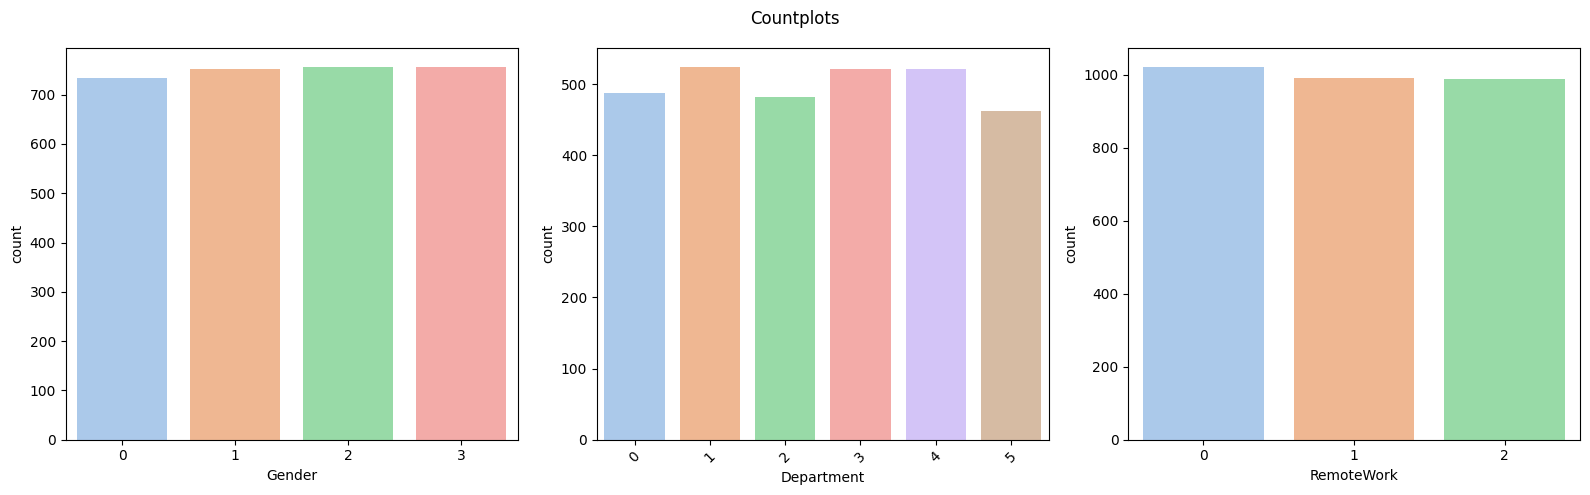

In [11]:
#countplot
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sns.countplot(data=df, x='Gender', ax=axes[0], palette='pastel')
sns.countplot(data=df, x='Department', ax=axes[1], palette='pastel')
sns.countplot(data=df, x='RemoteWork', ax=axes[2], palette='pastel')
axes[1].tick_params(axis='x', rotation=45)
plt.suptitle('Countplots')
plt.tight_layout()
plt.show()

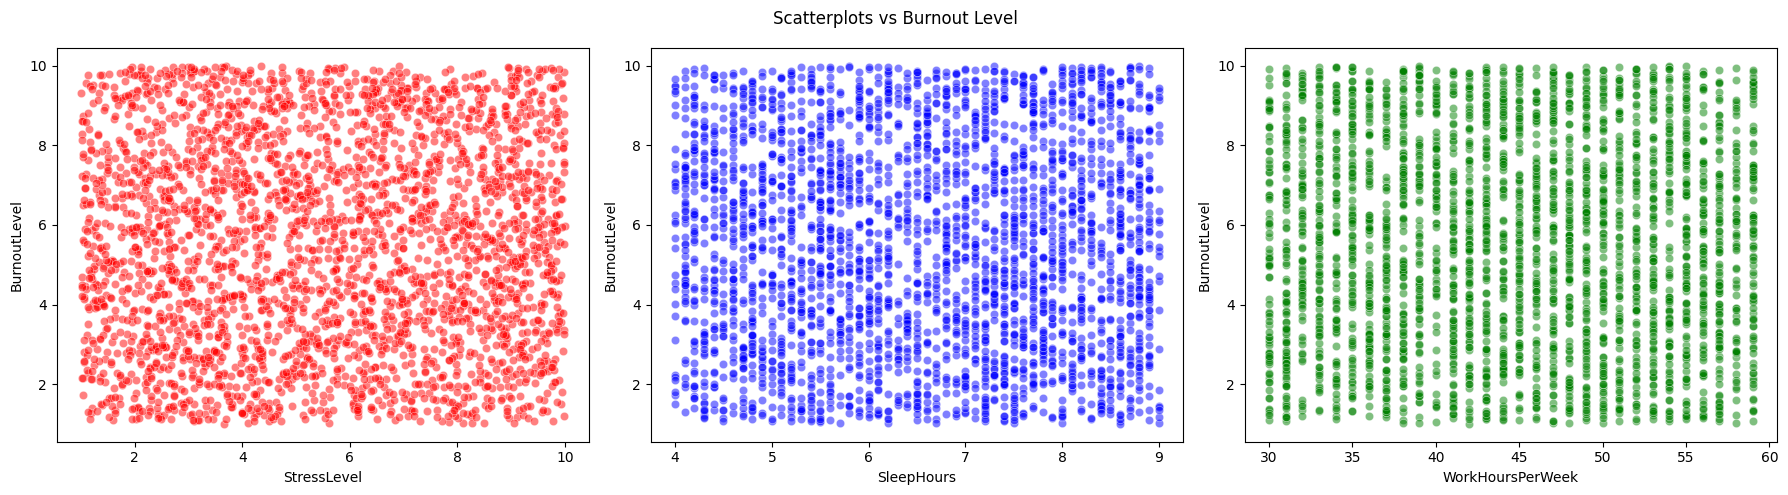

In [12]:
#scatterplot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=df, x='StressLevel', y='BurnoutLevel', ax=axes[0], color='red', alpha=0.5)
sns.scatterplot(data=df, x='SleepHours', y='BurnoutLevel', ax=axes[1], color='blue', alpha=0.5)
sns.scatterplot(data=df, x='WorkHoursPerWeek', y='BurnoutLevel', ax=axes[2], color='green', alpha=0.5)
plt.suptitle('Scatterplots vs Burnout Level')
plt.tight_layout()
plt.show()

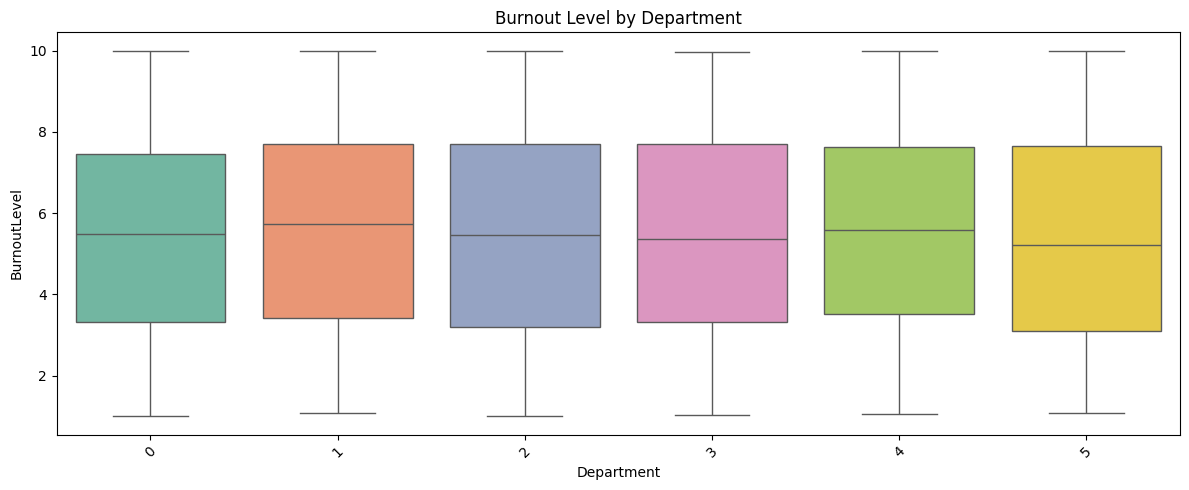

In [13]:
#boxplot
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x='Department', y='BurnoutLevel', palette='Set2')
plt.title('Burnout Level by Department')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [39]:
important_features = ['Age', 'Gender', 'YearsAtCompany', 
                      'WorkHoursPerWeek', 'RemoteWork',
                      'JobSatisfaction', 'StressLevel',
                      'SleepHours', 'CommuteTime',
                      'WorkLifeBalanceScore', 'CareerGrowthScore']

In [45]:
x = df[important_features]
y = df['BurnoutRisk']

In [46]:
x.head()

,Age,Gender,YearsAtCompany,WorkHoursPerWeek,RemoteWork,JobSatisfaction,StressLevel,SleepHours,CommuteTime,WorkLifeBalanceScore,CareerGrowthScore
0,50,1,14,47,1,5.06,9.47,7.0,117,8.82,9.20
1,36,1,1,59,0,2.00,5.65,7.2,8,2.80,8.46
2,29,2,13,59,0,7.17,5.70,5.2,75,7.28,7.96
3,42,1,15,31,2,3.76,6.40,8.7,43,1.31,8.90
4,40,1,6,34,2,2.34,3.41,4.2,58,1.17,8.88


In [41]:
y

0       0
1       1
2       1
3       0
4       1
       ..
2995    0
2996    0
2997    0
2998    0
2999    1
Name: BurnoutRisk, Length: 3000, dtype: int64

## Scaling

In [47]:
scaler=StandardScaler()
xs=scaler.fit_transform(x)
xs

array([[ 0.83509918, -0.45937671,  0.64644515, ...,  1.65995398,
         1.29481982,  1.43363182],
       [-0.43648715, -0.45937671, -1.50800374, ..., -1.47187203,
        -1.01883398,  1.14529388],
       [-1.07228031,  0.43725968,  0.48071831, ...,  0.45319534,
         0.7029549 ,  0.95047095],
       ...,
       [-1.70807347, -1.35601311, -1.67373058, ..., -0.9834221 ,
        -0.93043857,  0.55692862],
       [ 1.47089235,  0.43725968, -1.3422769 , ..., -1.01215445,
         0.21870178,  1.37908139],
       [ 0.4717888 ,  0.43725968,  1.14362567, ..., -0.29384573,
         0.9373949 , -1.72639613]], shape=(3000, 11))

In [64]:
xs=pd.DataFrame(xs,columns=x.columns)
xs.head()


,Age,Gender,YearsAtCompany,WorkHoursPerWeek,RemoteWork,JobSatisfaction,StressLevel,SleepHours,CommuteTime,WorkLifeBalanceScore,CareerGrowthScore
0,0.835099,-0.459377,0.646445,0.293989,0.013847,-0.145528,1.519164,0.319776,1.659954,1.294820,1.433632
1,-0.436487,-0.459377,-1.508004,1.707398,-1.207964,-1.325175,0.051725,0.458507,-1.471872,-1.018834,1.145294
2,-1.072280,0.437260,0.480718,1.707398,-1.207964,0.667888,0.070933,-0.928806,0.453195,0.702955,0.950471
3,0.108478,-0.459377,0.812172,-1.590556,1.235659,-0.646685,0.339835,1.498992,-0.466240,-1.591483,1.316738
4,-0.073177,-0.459377,-0.679370,-1.237204,1.235659,-1.194103,-0.808762,-1.622463,-0.035255,-1.645288,1.308945


In [65]:
#train and test data split
xtrain,xtest,ytrain,ytest=train_test_split(xs,y,test_size=0.3,random_state=1)


## Predictive Modeling

In [66]:
lr=LogisticRegression()
rf=RandomForestClassifier()
dt=DecisionTreeClassifier()
gr=GradientBoostingClassifier()
lists=[]
l=[lr,rf,dt,gr]
for i in l:
    print(i)
    i.fit(xtrain,ytrain)
    ypred=i.predict(xtest)
    lists.append(accuracy_score(ytest,ypred)*100)
    print(accuracy_score(ytest,ypred)*100)
print(lists)

LogisticRegression()
68.0
RandomForestClassifier()
67.11111111111111
DecisionTreeClassifier()
52.44444444444445
GradientBoostingClassifier()
67.0
[68.0, 67.11111111111111, 52.44444444444445, 67.0]


In [51]:
 print(y.value_counts())

BurnoutRisk
0    2020
1     980
Name: count, dtype: int64


In [67]:
print(x.columns.tolist())

['Age', 'Gender', 'YearsAtCompany', 'WorkHoursPerWeek', 'RemoteWork', 'JobSatisfaction', 'StressLevel', 'SleepHours', 'CommuteTime', 'WorkLifeBalanceScore', 'CareerGrowthScore']


In [52]:
print('Duplicates:',df.duplicated().sum())

Duplicates: 0


In [68]:
print(x.shape,y.shape)

(3000, 11) (3000,)


In [69]:
for col in xtrain.columns:
    unique_per_target = df.groupby(col)[y.name].nunique()
    if unique_per_target.max() == 1:
        print(f"LEAKING COLUMN: {col}")

In [70]:
print(classification_report(ytest,ypred))

              precision    recall  f1-score   support

           0       0.68      0.98      0.80       612
           1       0.29      0.02      0.04       288

    accuracy                           0.67       900
   macro avg       0.48      0.50      0.42       900
weighted avg       0.55      0.67      0.56       900



In [71]:
data=pd.DataFrame(lists,index=['LogisticRegression','RandomForest','DecisionTree','GradientBoosting'],columns=['default parameters'])
data

,default parameters
LogisticRegression,68.000000
RandomForest,67.111111
DecisionTree,52.444444
GradientBoosting,67.000000


In [27]:
#linear regression
#p = {'C': [0.01, 0.1, 1, 10],'solver': ['lbfgs', 'liblinear'], 'penalty': ['l2']}
#clf = GridSearchCV(LogisticRegression(max_iter=1000), p, cv=5, scoring='accuracy')
#clf.fit(xtrain, ytrain)
#print("LR best params:", clf.best_params_)

In [28]:
#randomforest
#p = {'n_estimators': [100, 150, 200],'max_depth': [1, 2, 3, 4, 5],'random_state': [1, 2, 3, 4, 5]}
#clf = GridSearchCV(RandomForestClassifier(), p, cv=5, scoring='accuracy')
#clf.fit(xtrain, ytrain)
#print("RF best params:", clf.best_params_)

In [29]:
#decisiontree
#p = {'criterion': ['gini', 'entropy'],'max_depth': [1, 2, 3, 4, 5],'random_state': [1, 2, 3, 4, 5]}
#clf = GridSearchCV(DecisionTreeClassifier(), p, cv=5, scoring='accuracy')
#clf.fit(xtrain, ytrain)
#print("DT best params:", clf.best_params_)

In [30]:
#gradientboosting
#p = {'n_estimators': [100, 150, 200],'max_depth': [1, 2, 3, 4, 5],'random_state': [1, 2, 3, 4, 5]}
#clf = GridSearchCV(GradientBoostingClassifier(), p, cv=5, scoring='accuracy')
#clf.fit(xtrain, ytrain)
#print("GB best params:", clf.best_params_)

In [57]:
lr1 = LogisticRegression(C=0.01, penalty='l2', solver='lbfgs')
rf1 = RandomForestClassifier(max_depth=1, n_estimators=100, random_state=1)
dt1 = DecisionTreeClassifier(criterion='gini', max_depth=1, random_state=1)
gr1 = GradientBoostingClassifier(max_depth=1, n_estimators=100, random_state=1)

lists1 = []
l1 =[lr1, rf1, dt1, gr1]

for i in l1:
    print(i)
    i.fit(xtrain, ytrain)
    ypred1 = i.predict(xtest)
    lists1.append(accuracy_score(ytest, ypred1) * 100)
    print(accuracy_score(ytest,ypred)*100)
print(lists)

LogisticRegression(C=0.01, penalty='l2')
67.55555555555556
RandomForestClassifier(max_depth=1, random_state=1)
67.55555555555556
DecisionTreeClassifier(max_depth=1, random_state=1)
67.55555555555556
GradientBoostingClassifier(max_depth=1, random_state=1)
67.55555555555556
[68.0, 67.88888888888889, 52.22222222222223, 67.55555555555556]


In [72]:
print(df.shape)
print(df.columns.tolist())
print(df['BurnoutRisk'].value_counts())

(3000, 25)
['EmployeeID', 'Age', 'Gender', 'Country', 'JobRole', 'Department', 'YearsAtCompany', 'WorkHoursPerWeek', 'RemoteWork', 'BurnoutLevel', 'JobSatisfaction', 'StressLevel', 'ProductivityScore', 'SleepHours', 'PhysicalActivityHrs', 'CommuteTime', 'HasMentalHealthSupport', 'ManagerSupportScore', 'HasTherapyAccess', 'MentalHealthDaysOff', 'SalaryRange', 'WorkLifeBalanceScore', 'TeamSize', 'CareerGrowthScore', 'BurnoutRisk']
BurnoutRisk
0    2020
1     980
Name: count, dtype: int64


In [73]:
# Checking the correlation
print(df[['BurnoutLevel', 'BurnoutRisk']].value_counts())

BurnoutLevel  BurnoutRisk
6.87          0              9
5.45          0              9
6.88          0              9
3.60          0              8
4.49          0              8
                            ..
4.71          0              1
2.35          0              1
3.34          0              1
4.92          0              1
3.95          0              1
Name: count, Length: 863, dtype: int64


BurnoutRisk               1.000000
BurnoutLevel              0.814620
JobRole                   0.028767
CommuteTime               0.025435
Gender                    0.013965
RemoteWork                0.010513
SalaryRange               0.010328
WorkLifeBalanceScore      0.004761
HasTherapyAccess          0.002265
StressLevel               0.001984
HasMentalHealthSupport    0.001602
TeamSize                  0.000102
Country                  -0.000554
Age                      -0.003328
CareerGrowthScore        -0.003918
JobSatisfaction          -0.004836
MentalHealthDaysOff      -0.005174
Department               -0.006177
YearsAtCompany           -0.007815
ProductivityScore        -0.011809
SleepHours               -0.012828
PhysicalActivityHrs      -0.012844
WorkHoursPerWeek         -0.017322
ManagerSupportScore      -0.020003
EmployeeID               -0.027493
Name: BurnoutRisk, dtype: float64


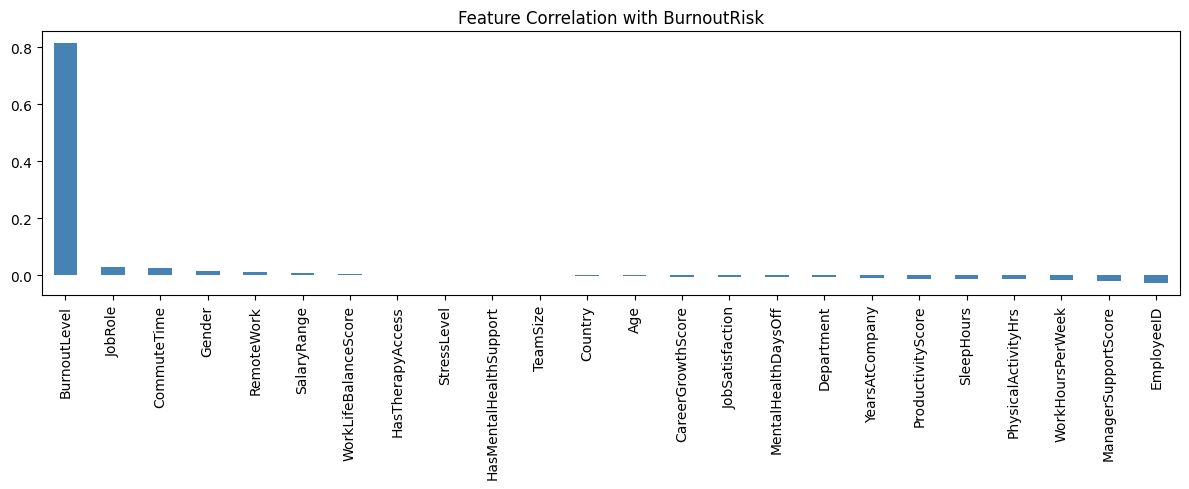

In [74]:
# Checking the correlation with target
corr = df.corr()['BurnoutRisk'].sort_values(ascending=False)
print(corr)

# Plotting it
corr.drop('BurnoutRisk').plot(kind='bar', figsize=(12,5), color='steelblue')
plt.title('Feature Correlation with BurnoutRisk')
plt.tight_layout()
plt.show()

In [75]:
print(xtrain.columns.tolist())

['Age', 'Gender', 'YearsAtCompany', 'WorkHoursPerWeek', 'RemoteWork', 'JobSatisfaction', 'StressLevel', 'SleepHours', 'CommuteTime', 'WorkLifeBalanceScore', 'CareerGrowthScore']


In [78]:
import pickle
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# the final model
scaler = StandardScaler()
xtrain_scaled = scaler.fit_transform(xtrain)
xtest_scaled = scaler.transform(xtest)

lr_final_model = LogisticRegression(C=0.01, penalty='l2', solver='lbfgs', max_iter=1000)
lr_final_model.fit(xtrain_scaled, ytrain)

print("Accuracy:", accuracy_score(ytest, lr_final_model.predict(xtest_scaled)) * 100)

# Save both
with open('burnout_model1.pkl', 'wb') as f:
    pickle.dump(lr_final_model, f)

with open('scaler_final.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print("Saved successfully!")

Accuracy: 68.0
Saved successfully!


In [77]:
print(xtrain.columns.tolist())
print("Total features:", xtrain.shape[1])

['Age', 'Gender', 'YearsAtCompany', 'WorkHoursPerWeek', 'RemoteWork', 'JobSatisfaction', 'StressLevel', 'SleepHours', 'CommuteTime', 'WorkLifeBalanceScore', 'CareerGrowthScore']
Total features: 11


In [79]:
print("xtrain features:", xtrain.shape[1])

xtrain features: 11


# Conclusion

This project focused on building an Employee Burnout Prediction system using machine learning classification algorithms Logistic Regression, Random Forest, Decision Tree, and Gradient Boosting.
The complete ML pipeline was followed, starting from data preprocessing and exploratory data analysis, to model building, hyperparameter tuning using GridSearchCV, evaluation and finally deployment.
Among all the models evaluated, Logistic Regression achieved the best accuracy of 68%. while this is moderate, it is justified given the complexity of predicting human behaviour from structured data. The deployed streamlit application allows anyone to input employee details and get instant burnout risk prediction.